# Assignment 4 - Deploying a DL model in an edge device

## Learning objectives

* The student configures and communicates with hardware and software present on a device
* The student exchanges data and messages between the device and various other data sources
* The student names and explains the choice of infrastructure or architecture for processing data
* The student selects and implements an appropriate solution for the transport or storage of data.
* The student applies mathematical operations to build AI/3D model
* The student implements the most efficient algorithm to build an AI application
* The student explains the choice of a framework.
* The student develops an interactive application using a framework or combination of frameworks

During this session we will deploy a computer vision model in an edge-device. You are free to choose the hardware, but the demo will be with a Raspberry Pi 4.

The pipeline consists on:

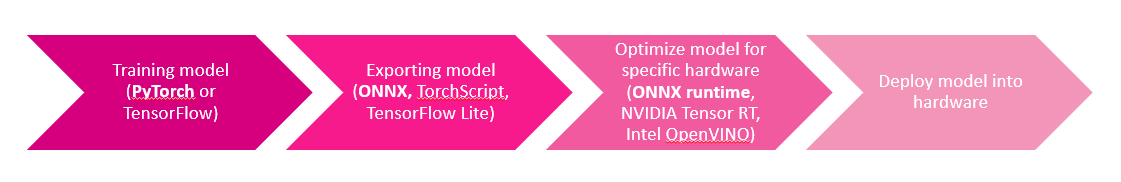

In the past assignments you have managed to compress a model using pruning and quantization techniques using PyTorch. Now, the trained model will be exported in onnx format to be used for the inference.

## Exporting a trained model as onnx file

In this demo, MobileNetV2 is used for classification of objects. This step is still carried out in your computer/colab.

In [1]:
# ! pip install onnx  (activate in case you don't have onnx yet)
import torch
import torchvision

model=torchvision.models.mobilenet_v2(pretrained=True).eval()
dummy_input=torch.randn(1,3,224,224)
torch.onnx.export(model,dummy_input,"onnx_mobinetv2.onnx",input_names=["input"],output_names=["output"],opset_version=13,do_constant_folding=True)

/home/student/venv/lib/python3.11/site-packages/torchvision/models/_utils.py:207: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/home/student/venv/lib/python3.11/site-packages/torchvision/models/_utils.py:222: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=MobileNet_V2_Weights.IMAGENET1K_V1`. You can also use `weights=MobileNet_V2_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/mobilenet_v2-b0353104.pth" to /home/student/.cache/torch/hub/checkpoints/mobilenet_v2-b0353104.pth


100.0%


ModuleNotFoundError: No module named 'onnxscript'

You will notice that a new file with extension *.onnx has been created in the same folder where this code is running. Later you can transfer this onnx file to your Raspberry Pi using either an USB or via Git.

## Setting up the Raspberry Pi

You will need to load an image of 64-bit in your RPi via the SD-card. If not yet installed, you may download it from here: official https://www.raspberrypi.com/software/.

Once you have the image in the SD-card, you may install it in the RPi, connect the camera and start your RPi.

After the OS boots and you complete the initial setup you’ll need to edit the /boot/firmware/config.txt file to enable the camera:


In [1]:
# This enables the extended features such as the camera.
start_x=1

# This needs to be at least 128M for the camera processing, if it's bigger you can just leave it as is.
gpu_mem=128

And then reboot.

Although the idea of this lab is to run the inference from onnx files, we will compare the speed with a model running with plane PyTorch - as RPi allows it. Therefore, we will need to install PyTorch and few other packages.

In [5]:
!sudo apt install -y python3-picamera2 python3-libcamera
!pip install torch torchvision opencv-python --break-system-packages

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
python3-picamera2 is already the newest version (0.3.31-1).
python3-libcamera is already the newest version (0.5.2+rpt20250903-1~bpo12+1).
0 upgraded, 0 newly installed, 0 to remove and 0 not upgraded.
Looking in indexes: https://pypi.org/simple, https://www.piwheels.org/simple
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.6/7.6 MB 3.4 MB/s eta 0:00:0000:0100:01


## Preparing the camera for capture

The camera capture will need to be set considering the input shape and dtype required by the model. Since MobileNetV2 is used in this demo, the resolution of the input is expected to be 224x224. Since the cameras cannot take any resolution value, the capture will be set to the closest resolution to the target (320x240), and once the image is capture, it will be resized to 224x224. We want the size difference between the captured image and the target size to be as small as possible, because the resizing is happening during the inference loop, which may slow down the process.

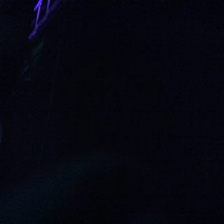

KeyboardInterrupt: 

In [2]:
import cv2
import torch
from torchvision import models,transforms
import time
import urllib.request
from torchprofile import profile_macs
import numpy as np

from IPython.display import display, clear_output
from PIL import Image

def show(img):
    # Show a frame inside the notebook (cv2.imshow crashes the kernel without a screen)
    clear_output(wait=True)
    display(Image.fromarray(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)))


cap=cv2.VideoCapture(0,cv2.CAP_V4L2)
cap.set(cv2.CAP_PROP_FOURCC,cv2.VideoWriter_fourcc('M','J','P','G'))

#set resolution
cap.set(cv2.CAP_PROP_FRAME_WIDTH,320)
cap.set(cv2.CAP_PROP_FRAME_HEIGHT,240)
cap.set(cv2.CAP_PROP_FPS,20)

actual_fps=cap.get(cv2.CAP_PROP_FPS)
actual_fwidth=cap.get(cv2.CAP_PROP_FRAME_WIDTH)
actual_fheight=cap.get(cv2.CAP_PROP_FRAME_HEIGHT)
print(f"Actual values: {actual_fps}x{actual_fwidth}x{actual_fheight}")


try:
    while True:
        ret,frame=cap.read()
        if not ret:
            print("Failed to grad frame")
            break
        resized_frame=cv2.resize(frame,(224,224),interpolation=cv2.INTER_LINEAR)
        print(f"Frame shape={resized_frame.shape}")
    
        show(resized_frame)
finally:
    cap.release()

You should see the captured image.

## Inference with PyTorch in RPi

Now that there are images in the right format, the inference can start.

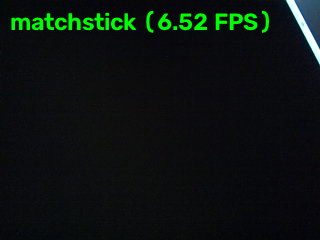

KeyboardInterrupt: 

In [3]:
import cv2
import torch
from torchvision import models,transforms
import time
import urllib.request
from torchprofile import profile_macs
import numpy as np

from IPython.display import display, clear_output
from PIL import Image

def show(img):
    # Show a frame inside the notebook (cv2.imshow crashes the kernel without a screen)
    clear_output(wait=True)
    display(Image.fromarray(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)))





cap=cv2.VideoCapture(0,cv2.CAP_V4L2)
cap.set(cv2.CAP_PROP_FOURCC,cv2.VideoWriter_fourcc('M','J','P','G'))

#set resolution
cap.set(cv2.CAP_PROP_FRAME_WIDTH,320)
cap.set(cv2.CAP_PROP_FRAME_HEIGHT,240)
cap.set(cv2.CAP_PROP_FPS,20)

actual_fps=cap.get(cv2.CAP_PROP_FPS)
actual_fwidth=cap.get(cv2.CAP_PROP_FRAME_WIDTH)
actual_fheight=cap.get(cv2.CAP_PROP_FRAME_HEIGHT)
print(f"Actual values: {actual_fps}x{actual_fwidth}x{actual_fheight}")

# MobileNetV2 expects also the images to be normalized
preproces=transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485,0.456,0.406],std=[0.229,0.224,0.225]),
    ])

net=models.mobilenet_v2(pretrained=True)
net.eval()

started=time.time()
last_logged=time.time()
frame_count=0

# Download the labels of ImageNet, used for the MobileNetV2 training
url="https://raw.githubusercontent.com/pytorch/hub/master/imagenet_classes.txt"
with urllib.request.urlopen(url) as f:
    classes = [line.decode('utf‑8').strip() for line in f.readlines()]

# Inference
try:
    with torch.no_grad():
        while True:
            ret,frame=cap.read()
            if not ret:
                print("Failed to grad frame")
                break
            resized_frame=cv2.resize(frame,(224,224),interpolation=cv2.INTER_LINEAR)
        
            #Preprocessing
            input_tensor=preproces(resized_frame)

            # Mini-batch as expected by model
            input_batch=input_tensor.unsqueeze(0)

            # Run the model
            output=net(input_batch)
        

            # Log model performance
            frame_count+=1
            now=time.time()
            if now-last_logged>1:
                print(f"{frame_count/(now-last_logged)} fps")
                last_logged=now
                frame_count=0

            top=list(enumerate(output[0].softmax(dim=0)))
            top.sort(key=lambda x:x[1],reverse=True)
            for idx,val in top[:10]:
                print(f"{val.item()*100:.2f}% {classes[idx]}")

            pred = np.argmax(output[0])
            class_name = classes[pred]
            fps = frame_count/max(now-last_logged, 1e-6)
        
            cv2.putText(frame, f"{class_name} ({fps:.2f} FPS)", (10, 30),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 255, 0), 2)
            show(frame)
finally:
    cap.release()

Notice the inference time using PyTorch. Keep that somewhere noted to compare with the inference time resulting from the ONNX runtime.

## Inference with ONNX runtime in RPi





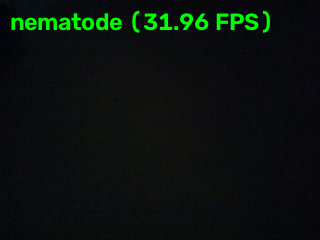

KeyboardInterrupt: 

In [4]:
# !pip install onnxruntime (Activate it in case you don't have it yet)

import time
import numpy as np
import onnxruntime as ort
import cv2
import urllib.request

from IPython.display import display, clear_output
from PIL import Image

def show(img):
    # Show a frame inside the notebook (cv2.imshow crashes the kernel without a screen)
    clear_output(wait=True)
    display(Image.fromarray(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)))


#activate video capture and set resolution and fps
cap=cv2.VideoCapture(0,cv2.CAP_V4L2)
cap.set(cv2.CAP_PROP_FOURCC,cv2.VideoWriter_fourcc('M','J','P','G'))
cap.set(cv2.CAP_PROP_FRAME_WIDTH,320)
cap.set(cv2.CAP_PROP_FRAME_HEIGHT,240)
cap.set(cv2.CAP_PROP_FPS,36)



def preprocessing(frame):
    mean=[0.485,0.456,0.406]
    std=[0.229,0.224,0.225]
    resized_frame=cv2.resize(frame,(224,224),interpolation=cv2.INTER_LINEAR)
    resized_frame=resized_frame.astype(np.float32)/255
    resized_frame=(resized_frame-mean)/std
    resized_frame=np.transpose(resized_frame,(2,0,1))
    resized_frame=np.expand_dims(resized_frame,axis=0)
    return resized_frame.astype(np.float32)


# Defining inference session
# When defining the session, bare in mind the hardware that you are using:
# RPi -->providers=['CPUExecutionProvider']
sess=ort.InferenceSession("onnx_mobinetv2.onnx", providers=['CPUExecutionProvider']) 
sess.intra_op_num_threads=4
sess.inter_op_num_threads=1

# Get model input details
input_name = sess.get_inputs()[0].name
input_shape = sess.get_inputs()[0].shape  # e.g., [1, 3, 224, 224]
output_name = sess.get_outputs()[0].name

# Get the labels of ImageNet
url="https://raw.githubusercontent.com/pytorch/hub/master/imagenet_classes.txt"
with urllib.request.urlopen(url) as f:
    classes = [line.decode('utf‑8').strip() for line in f.readlines()]


started=time.time()
last_logged=time.time()
frame_count=0

try:
    while True:
        ret,frame=cap.read()
        if not ret:
            print("Failed to grad frame")
            break

        input_tensor=preprocessing(frame)

        # Run the model
        inicio=time.time()
        output=sess.run([output_name],{input_name:input_tensor})
        inf_time=time.time()-inicio
        print(f'Inference time: {inf_time}')

        pred = np.argmax(output[0])
        class_name = classes[pred]
        fps = 1 / inf_time

        # Display result
        cv2.putText(frame, f"{class_name} ({fps:.2f} FPS)", (10, 30),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 255, 0), 2)

        show(frame)
finally:
    cap.release()

Compare the inference time using the two approaches, PyTorch on-device vs ONNX runtime. Are there differences?

Compare the inference time using the two approaches, PyTorch on-device vs ONNX runtime? With PyTorch it took around 78 ms per frame (about 13 fps), with ONNX runtime only around 20 ms (about 50 fps).

Are there differences? Yes, ONNX runtime is almost 4 times faster than PyTorch on the RPi, so it is a lot better for running the model on an edge device.

## Assignment

Once you have gone through the complete demo, it is time for the assignment.

Deploy one of the existing compact models in a RaspberryPi with an inference time higher than 36 fps. Apply quantization if needed!!!

In [5]:
import os
import cv2
import numpy as np
import torch
import torchvision
from onnxruntime.quantization import quantize_static, CalibrationDataReader, QuantType, QuantFormat
from onnxruntime.quantization.shape_inference import quant_pre_process

# MobileNetV3-small is a smaller model than MobileNetV2
model=torchvision.models.mobilenet_v3_small(weights="DEFAULT").eval()
dummy_input=torch.randn(1,3,224,224)
torch.onnx.export(model,dummy_input,"onnx_mobinetv3_small.onnx",input_names=["input"],output_names=["output"],opset_version=13,do_constant_folding=True,dynamo=False)


def preprocessing(frame):
    mean=[0.485,0.456,0.406]
    std=[0.229,0.224,0.225]
    resized_frame=cv2.resize(frame,(224,224),interpolation=cv2.INTER_LINEAR)
    resized_frame=cv2.cvtColor(resized_frame,cv2.COLOR_BGR2RGB)
    resized_frame=resized_frame.astype(np.float32)/255
    resized_frame=(resized_frame-mean)/std
    resized_frame=np.transpose(resized_frame,(2,0,1))
    resized_frame=np.expand_dims(resized_frame,axis=0)
    return resized_frame.astype(np.float32)


# Static quantization needs some example images, so we take them from the camera
class CameraCalibration(CalibrationDataReader):
    def __init__(self,n_frames=50):
        cap=cv2.VideoCapture(0,cv2.CAP_V4L2)
        cap.set(cv2.CAP_PROP_FOURCC,cv2.VideoWriter_fourcc('M','J','P','G'))
        cap.set(cv2.CAP_PROP_FRAME_WIDTH,320)
        cap.set(cv2.CAP_PROP_FRAME_HEIGHT,240)
        frames=[]
        for i in range(n_frames):
            ret,frame=cap.read()
            if ret:
                frames.append({"input":preprocessing(frame)})
        cap.release()
        print(f"Calibration frames: {len(frames)}")
        self.frames=iter(frames)

    def get_next(self):
        return next(self.frames,None)


# Quantize the model from float32 to int8
quant_pre_process("onnx_mobinetv3_small.onnx","onnx_mobinetv3_small_pre.onnx")
quantize_static("onnx_mobinetv3_small_pre.onnx","onnx_mobinetv3_small_int8.onnx",CameraCalibration(),
                quant_format=QuantFormat.QDQ,activation_type=QuantType.QUInt8,weight_type=QuantType.QInt8,per_channel=True)

print(f"Size float32 model: {os.path.getsize('onnx_mobinetv3_small.onnx')/1e6:.2f} MB")
print(f"Size int8 model: {os.path.getsize('onnx_mobinetv3_small_int8.onnx')/1e6:.2f} MB")

/tmp/ipykernel_10638/3726125657.py:12: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(model,dummy_input,"onnx_mobinetv3_small.onnx",input_names=["input"],output_names=["output"],opset_version=13,do_constant_folding=True,dynamo=False)


Calibration frames: 50
Size float32 model: 10.19 MB
Size int8 model: 2.91 MB


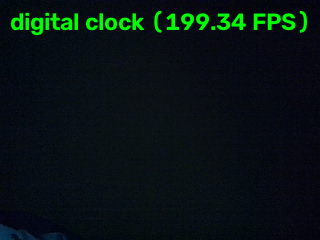

KeyboardInterrupt: 

In [6]:
import time
import numpy as np
import onnxruntime as ort
import cv2
import urllib.request

from IPython.display import display, clear_output
from PIL import Image

def show(img):
    clear_output(wait=True)
    display(Image.fromarray(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)))


# Get the labels of ImageNet
url="https://raw.githubusercontent.com/pytorch/hub/master/imagenet_classes.txt"
with urllib.request.urlopen(url) as f:
    classes = [line.decode('utf-8').strip() for line in f.readlines()]


def test_model(model_path,n_frames=200):
    cap=cv2.VideoCapture(0,cv2.CAP_V4L2)
    cap.set(cv2.CAP_PROP_FOURCC,cv2.VideoWriter_fourcc('M','J','P','G'))
    cap.set(cv2.CAP_PROP_FRAME_WIDTH,320)
    cap.set(cv2.CAP_PROP_FRAME_HEIGHT,240)
    cap.set(cv2.CAP_PROP_FPS,36)

    options=ort.SessionOptions()
    options.intra_op_num_threads=4
    options.inter_op_num_threads=1
    sess=ort.InferenceSession(model_path,options,providers=['CPUExecutionProvider'])
    input_name=sess.get_inputs()[0].name
    output_name=sess.get_outputs()[0].name

    inf_times=[]
    try:
        for i in range(n_frames):
            ret,frame=cap.read()
            if not ret:
                print("Failed to grab frame")
                break

            input_tensor=preprocessing(frame)

            start=time.time()
            output=sess.run([output_name],{input_name:input_tensor})
            inf_times.append(time.time()-start)

            pred=np.argmax(output[0])
            class_name=classes[pred]
            fps=1/inf_times[-1]

            cv2.putText(frame,f"{class_name} ({fps:.2f} FPS)",(10,30),
                        cv2.FONT_HERSHEY_SIMPLEX,0.8,(0,255,0),2)
            show(frame)
    finally:
        cap.release()

    # skip the first frames because the model is still warming up
    avg_time=np.mean(inf_times[10:])
    return avg_time


time_fp32=test_model("onnx_mobinetv3_small.onnx")
time_int8=test_model("onnx_mobinetv3_small_int8.onnx")

clear_output()
print(f"float32 model: {time_fp32*1000:.2f} ms -> {1/time_fp32:.2f} fps")
print(f"int8 model: {time_int8*1000:.2f} ms -> {1/time_int8:.2f} fps")